# Lab 3: Nim with Minimax and Alpha-Beta, plus a full EDA of the game data
Environment (Anaconda): `conda activate ailab`, then `jupyter notebook`. Run cells top to bottom with **Shift+Enter**.

**Game (Nim):** piles of stones; players A (MAX) and B (MIN) take turns; each turn you take 1 or more stones from ONE pile; whoever takes the last stone wins. Value: +1 A wins, -1 B wins.

**Part 1 (cells 1 to 4):** the game and the search. **Part 2 (cells 5 to 8):** Step 3 on real data: build a table of games, check quality, describe it, ask questions, plot, interpret.

## Cell 1: The game

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START = (2, 3, 4, 5)            # stones in each pile: the board of the game (Nim)
nodes = 0                    # how many positions the search looks at

def moves(piles, order="small_first"):
    """All positions we can reach by taking some stones from ONE pile."""
    result = []
    for i, n in enumerate(piles):
        takes = range(1, n + 1) if order == "small_first" else range(n, 0, -1)
        for take in takes:
            new = list(piles)
            new[i] = n - take
            result.append(tuple(new))
    return result

print(moves((1, 2)))

[(0, 2), (1, 1), (1, 0)]


## Cell 2: Minimax

In [12]:
def minimax(piles, player):
    """+1 if player A wins, -1 if player B wins (both play perfectly)."""
    global nodes
    nodes += 1
    if sum(piles) == 0:                     # the previous player took the last stone and won
        return -1 if player == "A" else 1
    values = [minimax(nxt, "B" if player == "A" else "A") for nxt in moves(piles)]
    return max(values) if player == "A" else min(values)

## Cell 3: Alpha-beta pruning

In [13]:
def alphabeta(piles, player, alpha, beta, order):
    global nodes
    nodes += 1
    if sum(piles) == 0:
        return -1 if player == "A" else 1
    if player == "A":
        value = -2
        for nxt in moves(piles, order):
            value = max(value, alphabeta(nxt, "B", alpha, beta, order))
            alpha = max(alpha, value)
            if alpha >= beta:
                break                      # prune: B will never allow this branch
        return value
    value = 2
    for nxt in moves(piles, order):
        value = min(value, alphabeta(nxt, "A", alpha, beta, order))
        beta = min(beta, value)
        if alpha >= beta:
            break                          # prune: A already has a better option
    return value

## Cell 4: Count the nodes

In [14]:
nodes = 0
v1 = minimax(START, "A")
n_minimax = nodes

nodes = 0
v2 = alphabeta(START, "A", -2, 2, "small_first")
n_ab = nodes

nodes = 0
v3 = alphabeta(START, "A", -2, 2, "big_first")
n_good = nodes

print("value of START (+1 = A wins):", v1, v2, v3)
print("minimax nodes:           ", n_minimax)
print("alpha-beta (natural):    ", n_ab)
print("alpha-beta (big first):  ", n_good)

value of START (+1 = A wins): -1 -1 -1
minimax nodes:            77978799
alpha-beta (natural):     6721725
alpha-beta (big first):   720038


## Cell 5: Build the data table (200 games) and save it as CSV

In [15]:
def best_move(piles, player):
    best_nxt, best_value = None, None
    for nxt in moves(piles, "big_first"):
        value = alphabeta(
            nxt,
            "B" if player == "A" else "A",
            -2, 2, "big_first"
        )
        better = (
            best_value is None or
            (value > best_value if player == "A" else value < best_value)
        )
        if better:
            best_nxt, best_value = nxt, value
    return best_nxt


rng = np.random.default_rng(0)
rows = []

for game in range(200):

    # Random start: 4 piles of 1..2 stones
    piles = tuple(int(x) for x in rng.integers(1, 5, size=4))

    nodes = 0
    start_value = alphabeta(piles, "A", -2, 2, "big_first")
    nodes_ab = nodes

    nodes = 0
    minimax(piles, "A")
    nodes_mm = nodes

    board, player, n_moves = piles, "A", 0

    # A plays smart, B plays randomly
    while sum(board) > 0:
        if player == "A":
            board = best_move(board, "A")
        else:
            options = moves(board)
            board = options[rng.integers(len(options))]

        player = "B" if player == "A" else "A"
        n_moves += 1

    rows.append({
        "p1": piles[0],
        "p2": piles[1],
        "p3": piles[2],
        "p4": piles[3],
        "total": sum(piles),
        "nim_sum": piles[0] ^ piles[1] ^ piles[2] ^ piles[3],
        "first_wins": start_value > 0,
        "nodes_minimax": nodes_mm,
        "nodes_alphabeta": nodes_ab,
        "moves": n_moves,
        "winner": "B" if player == "A" else "A"
    })

df = pd.DataFrame(rows)
df.to_csv("nim_games.csv", index=False)

print(df.head())

   p1  p2  p3  p4  total  nim_sum  first_wins  nodes_minimax  nodes_alphabeta  \
0   4   3   3   2     12        6        True        4832532             7475   
1   1   4   3   4     12        2        True        3086344            72462   
2   3   3   3   3     12        0       False        5767649            37398   
3   4   3   1   2     10        4        True         176618              383   
4   1   4   3   4     12        2        True        3086344            72462   

   moves winner  
0      9      A  
1      7      A  
2      5      A  
3      5      A  
4      9      A  


## Cell 6: Data quality and descriptive statistics

In [16]:
print(df.shape)                                       # rows, columns
print("missing values:", df.isna().sum().sum())
print("duplicated rows:", df.duplicated().sum())
print(df.dtypes)
print(df[["total", "nodes_minimax", "nodes_alphabeta", "moves"]].describe().round(1))
x = df["nodes_minimax"]
print("mean", round(x.mean(), 1), "| variance", round(x.var(), 1), "| std", round(x.std(), 1), "| median", x.median())

(200, 11)
missing values: 0
duplicated rows: 32
p1                  int64
p2                  int64
p3                  int64
p4                  int64
total               int64
nim_sum             int64
first_wins           bool
nodes_minimax       int64
nodes_alphabeta     int64
moves               int64
winner             object
dtype: object
       total  nodes_minimax  nodes_alphabeta  moves
count  200.0          200.0            200.0  200.0
mean    10.3     13000216.3         112436.4    6.6
std      2.0     62449727.2         385066.3    1.7
min      6.0          674.0             73.0    4.0
25%      9.0        42556.0            834.2    5.0
50%     11.0       659276.0           7475.0    7.0
75%     12.0      4050901.0          35203.8    7.0
max     15.0    496068200.0        2197848.0   13.0
mean 13000216.3 | variance 3899968425045984.5 | std 62449727.2 | median 659276.0


## Cell 7: Analytic questions

In [17]:
print("1) A wins from", round(df["first_wins"].mean() * 100), "% of the start positions")
print("2) nim_sum != 0 agrees with first_wins:", ((df["nim_sum"] != 0) == df["first_wins"]).mean())
print("3) alpha-beta uses", round(df["nodes_alphabeta"].sum() / df["nodes_minimax"].sum() * 100, 1), "% of the minimax nodes")
print("4) smart A wins", round((df["winner"] == "A").mean() * 100), "% of the games against a random B")
print(df[["total", "nodes_minimax", "nodes_alphabeta"]].corr().round(2))

1) A wins from 86 % of the start positions
2) nim_sum != 0 agrees with first_wins: 1.0
3) alpha-beta uses 0.9 % of the minimax nodes
4) smart A wins 100 % of the games against a random B
                 total  nodes_minimax  nodes_alphabeta
total             1.00           0.41             0.49
nodes_minimax     0.41           1.00             0.71
nodes_alphabeta   0.49           0.71             1.00


## Cell 8: Charts

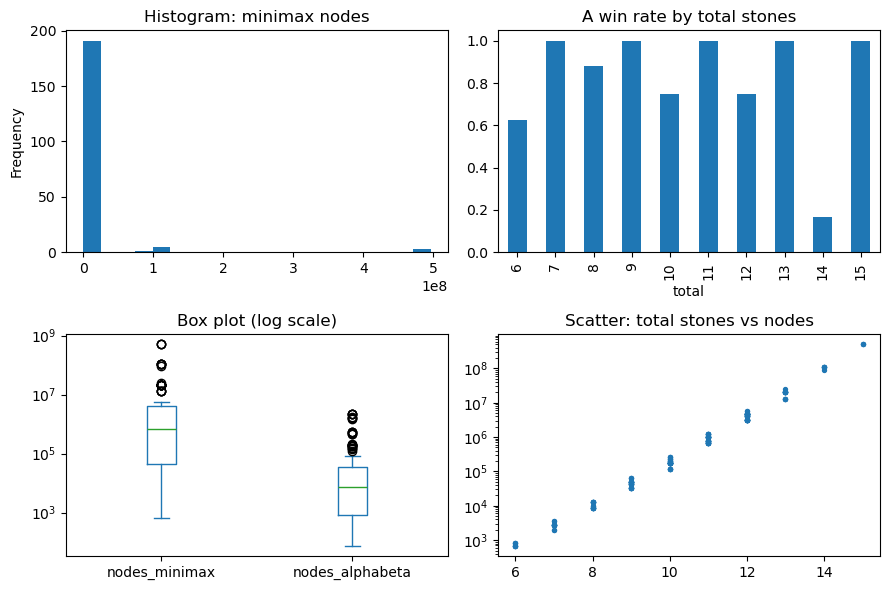

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
df["nodes_minimax"].plot(kind="hist", bins=20, ax=axes[0, 0], title="Histogram: minimax nodes")
df.groupby("total")["first_wins"].mean().plot(kind="bar", ax=axes[0, 1], title="A win rate by total stones")
df[["nodes_minimax", "nodes_alphabeta"]].plot(kind="box", logy=True, ax=axes[1, 0], title="Box plot (log scale)")
axes[1, 1].scatter(df["total"], df["nodes_minimax"], s=8)
axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Scatter: total stones vs nodes")
plt.tight_layout()
plt.show()

## Interpretation (write it yourself in README)
Use the pattern: **observation, reason, conclusion**. Example: *A wins from 88 percent of the starts (observation); most starts have nim_sum different from 0 (reason); so the first player has an advantage (conclusion).*

# Part 3: Motion output

## Cell 9: Animation of one game

In [19]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

rng = np.random.default_rng(1)
board, player = START, "A"
history = [(board, "start")]
while sum(board) > 0:
    old = board
    if player == "A":
        board = best_move(board, "A")
    else:
        options = moves(board)
        board = options[rng.integers(len(options))]
    i = [k for k in range(4) if board[k] != old[k]][0]
    history.append((board, f"{player} takes {old[i] - board[i]} from pile {i}"))
    player = "B" if player == "A" else "A"
winner = "B" if player == "A" else "A"

fig, ax = plt.subplots(figsize=(5, 3), dpi=70)

def draw(t):
    piles, text = history[min(t, len(history) - 1)]
    ax.clear()
    ax.bar(
    ["pile 0", "pile 1", "pile 2", "pile 3"],
    piles,
    color=["#4f46e5", "#ec4899", "#f59e0b", "#10b981"]
)
    ax.set_ylim(0, max(START) + 1)
    ax.set_title(text + ("   winner: " + winner if t >= len(history) - 1 else ""), fontsize=9)

anim = FuncAnimation(fig, draw, frames=len(history) + 3, interval=800)
plt.close(fig)
HTML(anim.to_jshtml())